# Dimensionality Reduction & Unsupervised Clustering
### Mall Customers Segmentation using PCA + K-Means

**Pipeline:** Standardize → PCA → Scree plot → K-Means (Elbow + Silhouette) → 2D/3D cluster visualizations

> Install once if needed: `pip install pandas numpy scikit-learn seaborn matplotlib plotly`

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score

sns.set_theme(style="whitegrid", palette="deep")
RANDOM_STATE = 42

## 1. Load the dataset
Place the Kaggle file `Mall_Customers.csv` next to this notebook. If the file is not found, a synthetic dataset with the **same columns and structure** is generated, so the notebook always runs.

In [1]:
import os

def make_synthetic_mall(seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    # (n, income mean/std, spending mean/std, age mean/std)
    groups = [
        (23, 25, 7, 20, 8, 45, 10),   # low income, low spending
        (22, 25, 7, 80, 8, 25, 5),    # low income, high spending
        (80, 55, 8, 50, 8, 43, 12),   # mid income, mid spending
        (35, 88, 12, 17, 8, 41, 10),  # high income, low spending
        (40, 86, 12, 82, 8, 32, 6),   # high income, high spending
    ]
    rows = []
    for n, im, isd, sm, ssd, am, asd in groups:
        inc = np.clip(rng.normal(im, isd, n), 15, 137)
        spd = np.clip(rng.normal(sm, ssd, n), 1, 99)
        age = np.clip(rng.normal(am, asd, n), 18, 70)
        rows.append(pd.DataFrame({"Age": age.round().astype(int),
                                  "Annual Income (k$)": inc.round().astype(int),
                                  "Spending Score (1-100)": spd.round().astype(int)}))
    df = pd.concat(rows, ignore_index=True).sample(frac=1, random_state=seed).reset_index(drop=True)
    df.insert(0, "CustomerID", np.arange(1, len(df) + 1))
    df.insert(1, "Gender", rng.choice(["Female", "Male"], len(df), p=[0.56, 0.44]))
    return df

if os.path.exists("Mall_Customers.csv"):
    df = pd.read_csv("Mall_Customers.csv")
    DATA_SOURCE = "Mall_Customers.csv (real data)"
else:
    df = make_synthetic_mall()
    DATA_SOURCE = "synthetic data (same schema as Mall Customers)"

print("Data source:", DATA_SOURCE)
print("Shape:", df.shape)
display(df.head())

Data source: synthetic data (same schema as Mall Customers)
Shape: (200, 5)
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1  Female   18                  67                      58
1           2    Male   42                  19                      13
2           3  Female   20                  22                      83
3           4  Female   41                  64                      28
4           5    Male   52                 107                      23

## 2. Quick EDA

In [2]:
df.info()
print()
display(df.describe().round(2))
print("\nMissing values per column:")
print(df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB

       CustomerID     Age  Annual Income (k$)  Spending Score (1-100)
count      200.00  200.00              200.00                  200.00
mean       100.50   39.51               59.73                   49.84
std         57.88   12.09               25.29                   25.19
min          1.00   18.00               15.00                    1.00
25%         50.75   30.00               44.75                   25.75
50%        100.50   39.00               57.50                   49.50
75%        15

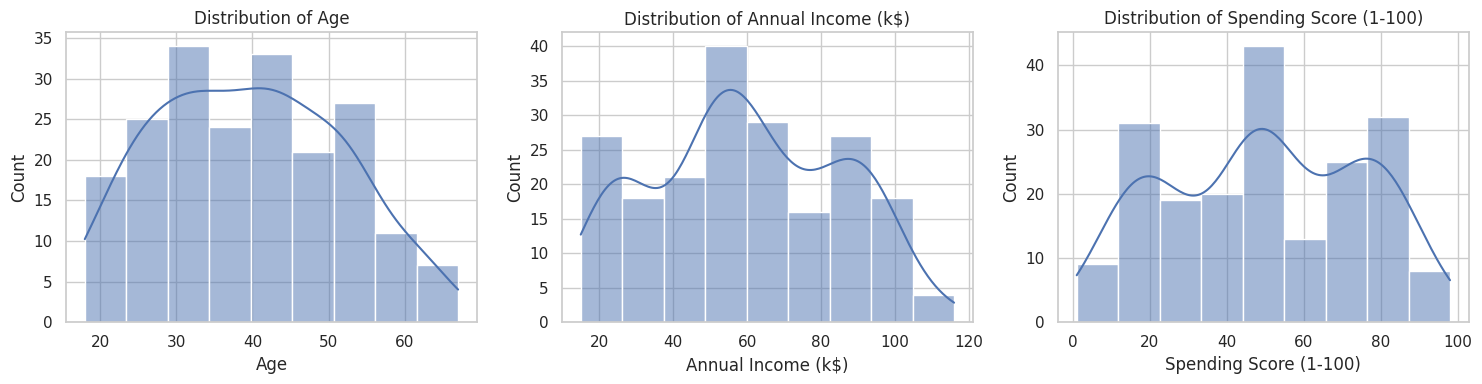

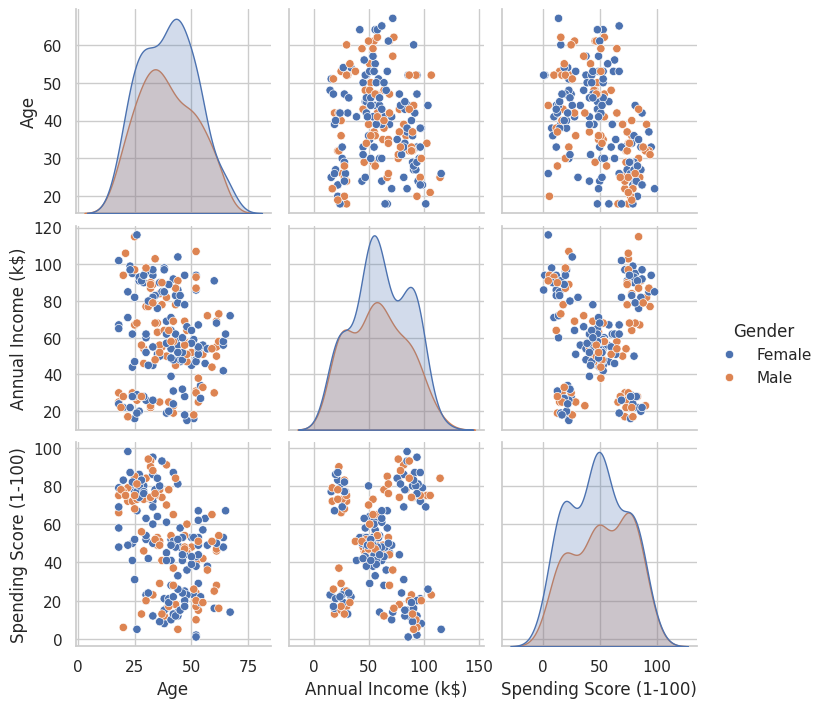

In [3]:
num_cols = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, num_cols):
    sns.histplot(df[c], kde=True, ax=ax)
    ax.set_title(f"Distribution of {c}")
plt.tight_layout()
plt.show()

sns.pairplot(df[num_cols + ["Gender"]], hue="Gender", height=2.4)
plt.show()

## 3. Standardize features
PCA and K-Means are distance/variance based, so every feature must be on the same scale. Only the numerical features are used for PCA/clustering; `Gender` is a binary label that adds noise to distances, so it is kept aside and used only for profiling the clusters.

In [4]:
features = df[["Age", "Annual Income (k$)", "Spending Score (1-100)"]].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)
print("Feature matrix shape:", X_scaled.shape)
print("Means after scaling:", X_scaled.mean(axis=0).round(3))
print("Std after scaling  :", X_scaled.std(axis=0).round(3))

Feature matrix shape: (200, 3)
Means after scaling: [-0.  0. -0.]
Std after scaling  : [1. 1. 1.]

## 4. PCA and Explained Variance Ratio (scree plot)

    PC  Explained Variance Ratio  Cumulative
0  PC1                    0.4864      0.4864
1  PC2                    0.3320      0.8183
2  PC3                    0.1817      1.0000
Smallest number of components reaching >= 80% variance: 2

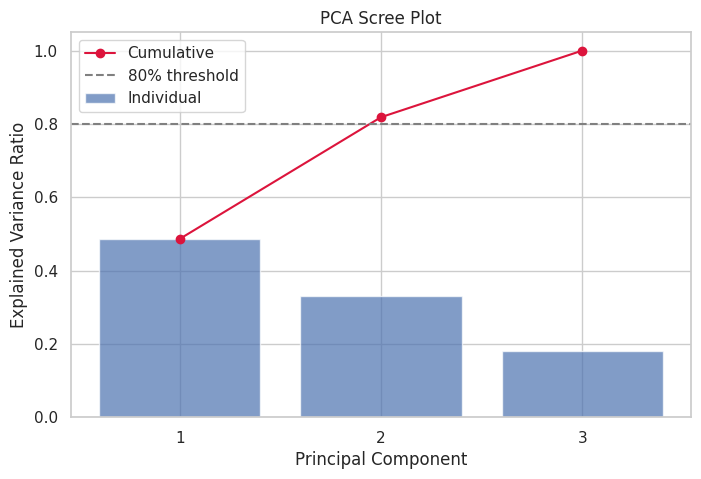

In [5]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_scaled)
evr = pca_full.explained_variance_ratio_
cum_evr = np.cumsum(evr)

evr_table = pd.DataFrame({
    "PC": [f"PC{i+1}" for i in range(len(evr))],
    "Explained Variance Ratio": evr.round(4),
    "Cumulative": cum_evr.round(4),
})
display(evr_table)

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(range(1, len(evr) + 1), evr, alpha=0.7, label="Individual")
ax.plot(range(1, len(evr) + 1), cum_evr, "o-", color="crimson", label="Cumulative")
ax.axhline(0.80, ls="--", color="gray", label="80% threshold")
ax.set_xticks(range(1, len(evr) + 1))
ax.set_xlabel("Principal Component")
ax.set_ylabel("Explained Variance Ratio")
ax.set_title("PCA Scree Plot")
ax.legend()
plt.show()

n_opt = int(np.argmax(cum_evr >= 0.80) + 1)
print(f"Smallest number of components reaching >= 80% variance: {n_opt}")

Using 3 components, total variance retained: 100.00%

Feature loadings:
                          PC1    PC2    PC3
Age                     0.705  0.028  0.708
Annual Income (k$)     -0.129  0.988  0.090
Spending Score (1-100) -0.697 -0.155  0.700

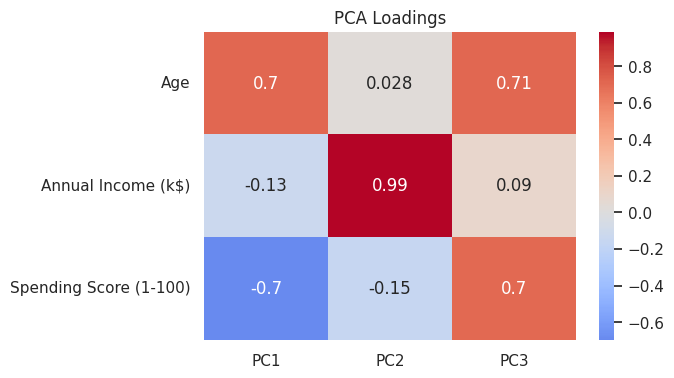

In [6]:
# Keep at least 3 components so that a 3D projection is possible
n_components = max(n_opt, 3)
pca = PCA(n_components=n_components, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print(f"Using {n_components} components, total variance retained: {pca.explained_variance_ratio_.sum():.2%}")

loadings = pd.DataFrame(pca.components_.T,
                        index=features.columns,
                        columns=[f"PC{i+1}" for i in range(n_components)]).round(3)
print("\nFeature loadings:")
display(loadings)

plt.figure(figsize=(6, 4))
sns.heatmap(loadings, annot=True, cmap="coolwarm", center=0)
plt.title("PCA Loadings")
plt.show()

## 5. K-Means: choosing k (Elbow Method + Silhouette Score)

    k  Inertia (WCSS)  Silhouette
0   2          368.58      0.3572
1   3          274.68      0.3734
2   4          191.70      0.4191
3   5          146.93      0.4413
4   6          114.51      0.4417
5   7          101.10      0.4057
6   8           88.95      0.4006
7   9           82.38      0.3922
8  10           73.68      0.3742
Best k by silhouette score: 6

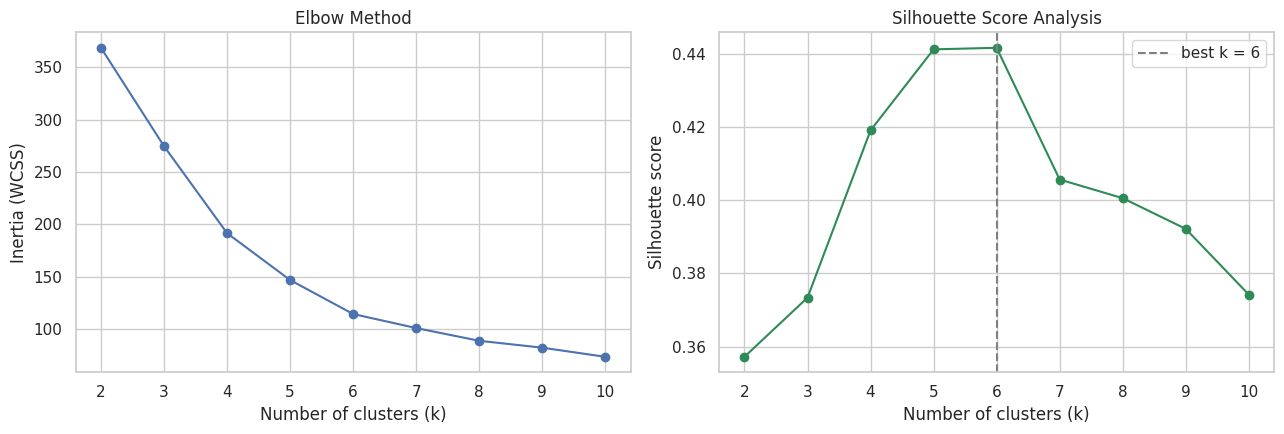

In [7]:
k_range = range(2, 11)
inertias, sil_scores = [], []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_pca)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_pca, km.labels_))

k_table = pd.DataFrame({"k": list(k_range),
                        "Inertia (WCSS)": np.round(inertias, 2),
                        "Silhouette": np.round(sil_scores, 4)})
display(k_table)

best_k = list(k_range)[int(np.argmax(sil_scores))]
print(f"Best k by silhouette score: {best_k}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(list(k_range), inertias, "o-")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia (WCSS)")

axes[1].plot(list(k_range), sil_scores, "o-", color="seagreen")
axes[1].axvline(best_k, ls="--", color="gray", label=f"best k = {best_k}")
axes[1].set_title("Silhouette Score Analysis")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
axes[1].legend()
plt.tight_layout()
plt.show()

## 6. Final K-Means model

In [8]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE).fit(X_pca)
df["Cluster"] = kmeans.labels_

sil = silhouette_score(X_pca, kmeans.labels_)
dbi = davies_bouldin_score(X_pca, kmeans.labels_)
print(f"k = {best_k}")
print(f"Silhouette score    : {sil:.4f}  (higher is better)")
print(f"Davies-Bouldin index: {dbi:.4f}  (lower is better)")

print("\nCluster sizes:")
print(df["Cluster"].value_counts().sort_index())

print("\nCluster profile (mean of original features):")
profile = df.groupby("Cluster")[["Age", "Annual Income (k$)", "Spending Score (1-100)"]].mean().round(1)
display(profile)

k = 6
Silhouette score    : 0.4417  (higher is better)
Davies-Bouldin index: 0.7810  (lower is better)

Cluster sizes:
Cluster
0    32
1    37
2    22
3    50
4    35
5    24
Name: count, dtype: int64

Cluster profile (mean of original features):
          Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                  
0        40.3                87.6                    15.6
1        30.7                87.9                    81.7
2        24.4                24.1                    76.8
3        53.4                55.9                    46.7
4        33.6                55.7                    54.1
5        45.5                25.7                    21.8

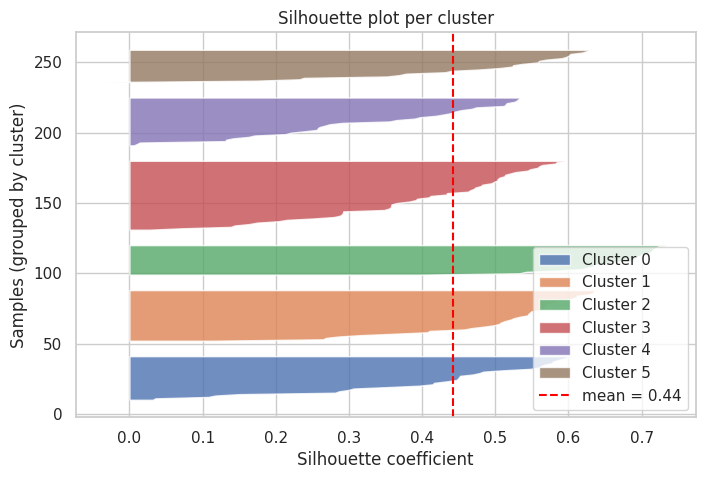

In [9]:
# Silhouette plot per cluster
sample_sil = silhouette_samples(X_pca, kmeans.labels_)
fig, ax = plt.subplots(figsize=(8, 5))
y_lower = 10
for c in range(best_k):
    vals = np.sort(sample_sil[kmeans.labels_ == c])
    y_upper = y_lower + len(vals)
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, vals, alpha=0.8, label=f"Cluster {c}")
    y_lower = y_upper + 10
ax.axvline(sil, color="red", ls="--", label=f"mean = {sil:.2f}")
ax.set_xlabel("Silhouette coefficient")
ax.set_ylabel("Samples (grouped by cluster)")
ax.set_title("Silhouette plot per cluster")
ax.legend(loc="lower right")
plt.show()

## 7. Cluster visualizations

### 7.1 2D projections (Seaborn)

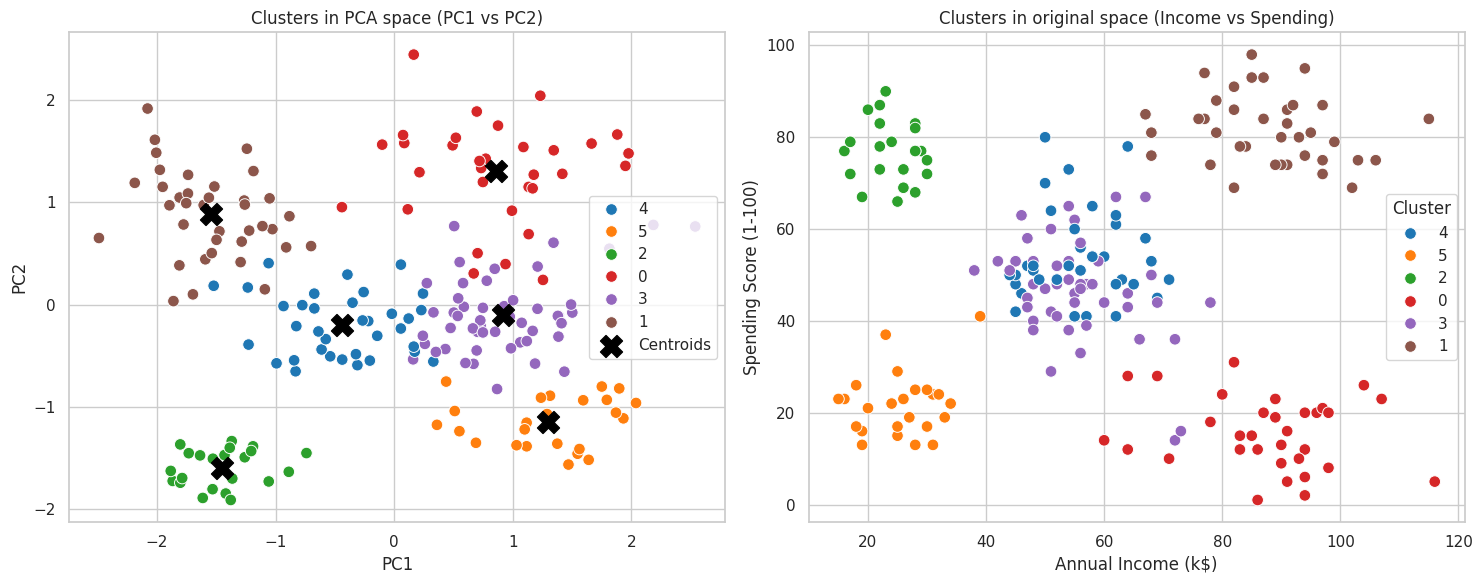

In [10]:
pca_df = pd.DataFrame(X_pca[:, :3], columns=["PC1", "PC2", "PC3"])
pca_df["Cluster"] = df["Cluster"].astype(str)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Cluster", palette="tab10", s=70, ax=axes[0])
centers = kmeans.cluster_centers_
axes[0].scatter(centers[:, 0], centers[:, 1], c="black", marker="X", s=250, label="Centroids")
axes[0].set_title("Clusters in PCA space (PC1 vs PC2)")
axes[0].legend()

sns.scatterplot(data=df.assign(Cluster=df["Cluster"].astype(str)),
                x="Annual Income (k$)", y="Spending Score (1-100)",
                hue="Cluster", palette="tab10", s=70, ax=axes[1])
axes[1].set_title("Clusters in original space (Income vs Spending)")
plt.tight_layout()
plt.show()

### 7.2 3D projection (static, Matplotlib)

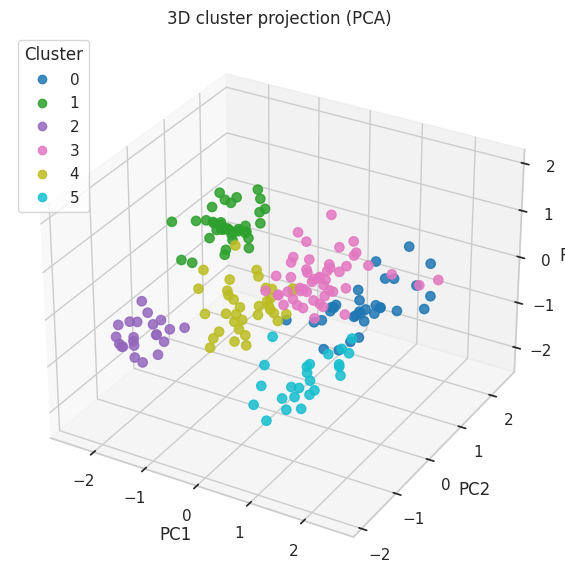

In [11]:
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
sc = ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2],
                c=df["Cluster"], cmap="tab10", s=45, alpha=0.85)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3")
ax.set_title("3D cluster projection (PCA)")
ax.legend(*sc.legend_elements(), title="Cluster", loc="upper left")
plt.show()

### 7.3 Interactive 2D / 3D projections (Plotly)

In [ ]:
plot_df = pca_df.copy()
plot_df["Age"] = df["Age"]
plot_df["Income"] = df["Annual Income (k$)"]
plot_df["Spending"] = df["Spending Score (1-100)"]

fig2d = px.scatter(plot_df, x="PC1", y="PC2", color="Cluster",
                   hover_data=["Age", "Income", "Spending"],
                   title="Interactive 2D cluster projection (PCA)")
fig2d.update_traces(marker=dict(size=9, line=dict(width=0.5, color="white")))
fig2d.show()

fig3d = px.scatter_3d(plot_df, x="PC1", y="PC2", z="PC3", color="Cluster",
                      hover_data=["Age", "Income", "Spending"],
                      title="Interactive 3D cluster projection (PCA)")
fig3d.update_traces(marker=dict(size=4))
fig3d.show()

## 8. Summary

In [12]:
print(f"Data source              : {DATA_SOURCE}")
print(f"Input features           : {list(features.columns)}")
print(f"PCA components used      : {n_components} ({pca.explained_variance_ratio_.sum():.1%} variance retained)")
print(f"Optimal k (silhouette)   : {best_k}")
print(f"Final silhouette score   : {sil:.3f}")
print(f"Davies-Bouldin index     : {dbi:.3f}")
print()
print("Customer segments (cluster means):")
display(profile.assign(Size=df['Cluster'].value_counts().sort_index()))

Data source              : synthetic data (same schema as Mall Customers)
Input features           : ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
PCA components used      : 3 (100.0% variance retained)
Optimal k (silhouette)   : 6
Final silhouette score   : 0.442
Davies-Bouldin index     : 0.781

Customer segments (cluster means):
          Age  Annual Income (k$)  Spending Score (1-100)  Size
Cluster                                                        
0        40.3                87.6                    15.6    32
1        30.7                87.9                    81.7    37
2        24.4                24.1                    76.8    22
3        53.4                55.9                    46.7    50
4        33.6                55.7                    54.1    35
5        45.5                25.7                    21.8    24